# #19 Cohort Curve

Your task is to group subscribers into cohorts by signup month and calculate each cohort’s retention rate after 1 month, 2 months, 3 months, and so on.

A few rules to keep in mind:

* Treat each subscription record independently. If a customer cancels and later resubscribes, each subscription belongs to the cohort associated with its own signup date.

* A subscription is only considered retained after N months if it remained active beyond the corresponding monthly renewal date. If the cancellation date falls exactly on that date, do not count it as retained.

* Subscriptions with no cancellation date should be treated as active through the latest applicable month in the analysis.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
_df = pd.read_csv("cohort_curve.csv", parse_dates=["created_date","canceled_date"]) # Rename dataset "streaming_subscriptions.csv"

In [3]:
_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19102 entries, 0 to 19101
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   subscription_id  19102 non-null  int64         
 1   customer_id      19102 non-null  int64         
 2   created_date     19102 non-null  datetime64[us]
 3   canceled_date    15124 non-null  datetime64[us]
dtypes: datetime64[us](2), int64(2)
memory usage: 597.1 KB


In [4]:
data = _df.copy()

In [5]:
data.sort_values(by="customer_id")

,subscription_id,customer_id,created_date,canceled_date
0,500001,100002,2025-01-01,2025-02-03
4784,504785,100002,2025-07-21,2025-08-17
20,500021,100004,2025-01-01,2025-08-27
19,500020,100006,2025-01-01,2025-01-03
18,500019,100008,2025-01-01,2025-02-19
...,...,...,...,...
19075,519076,127657,2026-07-31,NaT
19076,519077,127659,2026-07-31,NaT
19077,519078,127660,2026-07-31,NaT
19083,519084,127661,2026-07-31,NaT


In [6]:
data.describe()

,subscription_id,customer_id,created_date,canceled_date
count,19102.000000,19102.000000,19102,15124
mean,509551.500000,113600.200450,2025-11-27 04:00:37.692388,2025-12-18 16:16:41.639777
min,500001.000000,100002.000000,2025-01-01 00:00:00,2025-01-02 00:00:00
25%,504776.250000,106697.250000,2025-07-21 00:00:00,2025-08-23 00:00:00
50%,509551.500000,113486.500000,2025-12-16 00:00:00,2026-01-07 00:00:00
75%,514326.750000,120455.750000,2026-04-16 00:00:00,2026-04-28 00:00:00
max,519102.000000,127663.000000,2026-07-31 00:00:00,2026-08-03 00:00:00
std,5514.416757,7967.501739,NaN,NaN


In [7]:
round((data.canceled_date.max() - data.created_date.min()).days/30,0)

19.0

In [8]:
analysis_end = max(
    data["created_date"].max(),
    data["canceled_date"].max()
) + pd.Timedelta(days=1)

# max_months = int(round((data.canceled_date.max() - data.created_date.min()).days/30,0)) #maximum range of dataset
max_months = 12

analysis_end, max_months

(Timestamp('2026-08-04 00:00:00'), 12)

In [9]:
data = data[data["created_date"] < analysis_end].copy()         # Only subscitions created befor analysis end date
data["cohort"] = data["created_date"].dt.to_period("M")

cohort_size = data.groupby("cohort").size()
result = pd.DataFrame(index=cohort_size.index)

for n in range(1, max_months + 1):
    
    renewal = data["created_date"] + pd.DateOffset(months=n)    # Data ntego odnowienia subskrypcji
    
    complete = (                                                # Czy wszystkie subskrypcje kohorty osiągnęły już wymagany wiek?
            (renewal < analysis_end)
            .groupby(data["cohort"])
            .all()
        )
  
    active = (                                                  # Subskrypcja musi przetrwać datę odnowienia
            data["canceled_date"].isna()
            | (data["canceled_date"] > renewal)
        )
    
    retention = active.groupby(data["cohort"]).mean()           # Procent zachowanych subskrypcji
    result[f"M{n}"] = retention.where(complete)                 # Nie pokazujemy niekompletnych miesięcy

    
result.mul(100).round(1).fillna("")


,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11,M12
cohort,,,,,,,,,,,,
2025-01,53.3,38.7,30.8,24.3,20.9,17.7,14.1,12.6,10.9,9.4,8.1,6.8
2025-02,52.3,37.1,27.9,22.7,18.4,15.0,12.0,10.7,9.7,8.7,7.5,6.2
2025-03,52.1,38.9,31.8,25.5,21.7,17.2,14.6,13.3,11.7,10.1,8.9,7.2
2025-04,53.9,37.9,30.4,23.9,21.0,17.6,14.8,12.7,11.1,8.9,7.9,6.6
2025-05,54.7,40.8,31.7,23.8,19.4,16.2,14.2,12.0,10.1,9.0,8.3,7.2
2025-06,56.8,40.6,31.2,25.6,20.8,17.5,15.1,13.1,11.1,9.2,8.0,7.2
2025-07,52.9,37.6,29.2,24.7,21.1,18.3,15.4,12.6,11.2,9.1,8.3,7.7
2025-08,56.0,40.1,31.4,24.8,21.1,17.3,15.4,12.3,10.8,10.0,8.5,
2025-09,53.9,39.6,31.9,24.1,19.1,16.5,13.5,12.4,10.6,9.1,,


In [10]:
result.loc["2025-11","M3"]

np.float64(0.30362116991643456)

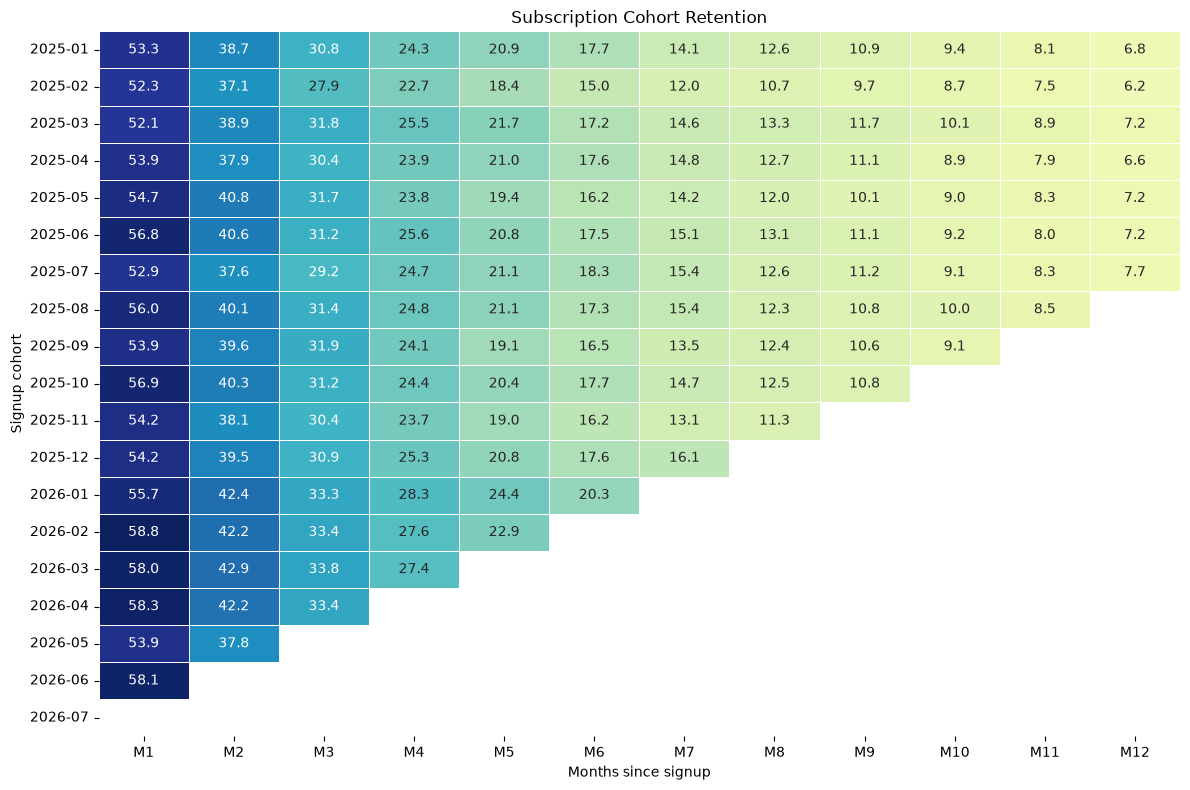

In [11]:
heatmap_data = result.mul(100).copy()
heatmap_data.index = heatmap_data.index.astype(str)

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=60,
    mask=heatmap_data.isna(),
    linewidths=0.5,
    cbar=False
)

plt.title("Subscription Cohort Retention")
plt.xlabel("Months since signup")
plt.ylabel("Signup cohort")
plt.tight_layout()
plt.show()


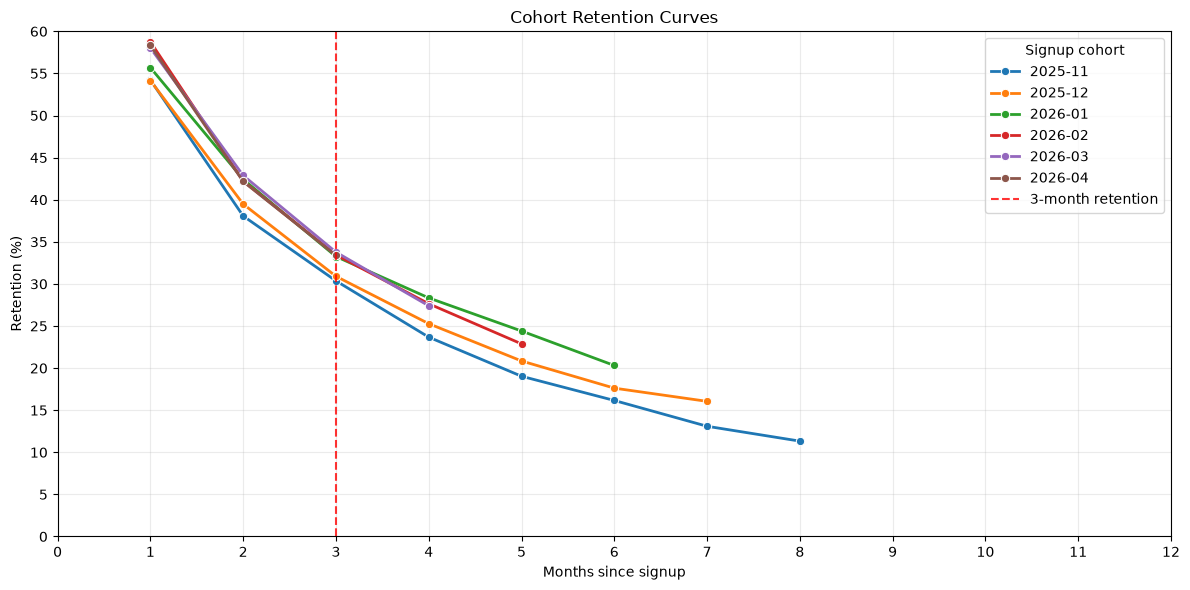

In [12]:
selected = result[result["M3"].notna()].tail(6).copy()

curve_data = (
    selected
    .reset_index()
    .melt(
        id_vars="cohort",
        var_name="month",
        value_name="retention"
    )
)

curve_data["cohort"] = curve_data["cohort"].astype(str)
curve_data["month"] = (
    curve_data["month"].str.replace("M", "").astype(int)
)
curve_data["retention"] *= 100

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=curve_data,
    x="month",
    y="retention",
    hue="cohort",
    marker="o",
    linewidth=2
)

plt.axvline(
    x=3,
    color="red",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="3-month retention"
)

plt.title("Cohort Retention Curves")
plt.xlabel("Months since signup")
plt.ylabel("Retention (%)")
plt.ylim(0, 60)
plt.yticks(range(0, 61, 5))
plt.xticks(range(max_months + 1))
plt.grid(alpha=0.25)
plt.legend(title="Signup cohort")
plt.tight_layout()
plt.show()


In [13]:
selected.index

PeriodIndex(['2025-11', '2025-12', '2026-01', '2026-02', '2026-03', '2026-04'], dtype='period[M]', name='cohort')